In [1]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,),(0.3081,))
])

train_ds = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_size = int(0.9 * len(train_ds))
val_size = len(train_ds) - train_size
train_set, val_set = random_split(train_ds, [train_size, val_size])

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)


100.0%
100.0%
100.0%
100.0%


In [2]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.cuda.is_available())

True


In [5]:
import torch.nn as nn
import torch.nn.functional as F

class MNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


In [6]:
criterion = nn.CrossEntropyLoss()
model = MNIST_CNN().to(device)
criterion = criterion.to(device)

import torch.optim as optim
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [9]:
epochs = 5

# train
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    correct = 0
    total = 0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, pred = out.max(1)
        correct += pred.eq(y).sum().item()
        total += y.size(0)

    train_acc = correct / total

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            out = model(x)
            loss = criterion(out, y)

            val_loss += loss.item()
            _, pred = out.max(1)
            val_correct += pred.eq(y).sum().item()
            val_total += y.size(0)
    val_acc = val_correct / val_total

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss/len(train_loader):.4f} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss/len(val_loader):.4f} | "
          f"Val Acc: {val_acc:.4f}")

    

Epoch 1/5 | Train Loss: 0.1367 | Train Acc: 0.9583 | Val Loss: 0.0486 | Val Acc: 0.9847
Epoch 2/5 | Train Loss: 0.0428 | Train Acc: 0.9864 | Val Loss: 0.0514 | Val Acc: 0.9835
Epoch 3/5 | Train Loss: 0.0299 | Train Acc: 0.9904 | Val Loss: 0.0379 | Val Acc: 0.9880
Epoch 4/5 | Train Loss: 0.0223 | Train Acc: 0.9929 | Val Loss: 0.0374 | Val Acc: 0.9890
Epoch 5/5 | Train Loss: 0.0180 | Train Acc: 0.9941 | Val Loss: 0.0618 | Val Acc: 0.9832


Test Accuracy: 0.9832


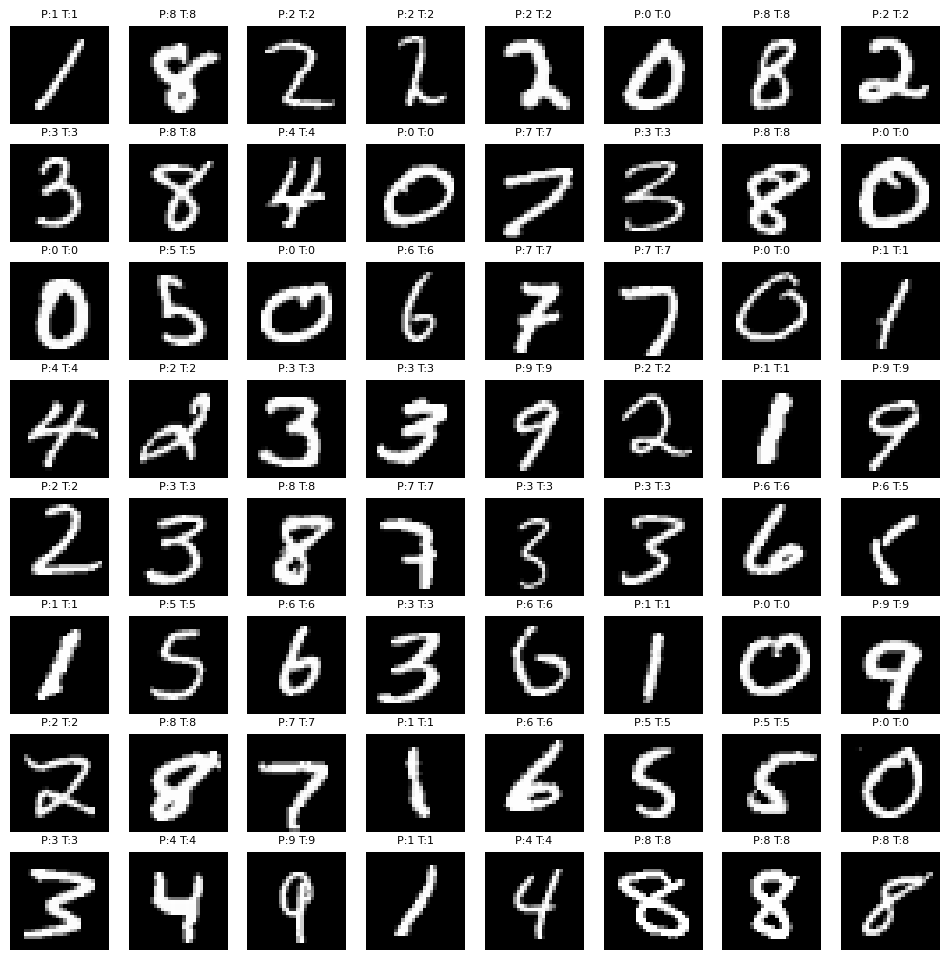

In [12]:
# evaluation
model.eval()
eval_correct = 0
eval_total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        out = model(x)
        _, pred = out.max(1)

        eval_correct += pred.eq(y).sum().item()
        eval_total += y.size(0)

        all_preds.append(pred.cpu())
        all_labels.append(y.cpu)
eval_acc = eval_correct / eval_total
print(f"Test Accuracy: {eval_acc:.4f}")


import random
import matplotlib.pyplot as plt

model.eval()
images = []
labels = []
preds = []
grid = 8

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        out = model(x)
        _, p = out.max(1)

        images.append(x.cpu())
        labels.append(y)
        preds.append(p.cpu())

images = torch.cat(images)
labels = torch.cat(labels)
preds  = torch.cat(preds)

idx = random.sample(range(len(images)), grid*grid)

plt.figure(figsize=(12,12))
for i, j in enumerate(idx):
    plt.subplot(grid, grid, i+1)
    plt.imshow(images[j][0], cmap="gray")
    plt.title(f"P:{preds[j].item()} T:{labels[j].item()}", fontsize=8)
    plt.axis("off")
plt.show()

